# PINNs for the surface vessel (ODE)

A physics-informed neural network bakes the equations of motion into the loss as a
*residual*, so the network is trained to satisfy the physics rather than to fit logged
trajectories. On the vessel we exercise the four things PINNs are actually good at:

1. **forward solve** of the surge coast-down with a hard initial condition,
2. **inverse problem** — recover an unknown damping coefficient from noisy data,
3. **identifiability** — which coefficients the data can and cannot pin down, and why
   *excitation* decides it,
4. the **full 3-DOF** forward solve (surge–sway–yaw together),
5. a **grey-box** PINN that identifies a misspecified physics term — a preview of
   CoSTA (Chapter~\ref{ch:costa}).

Ground truth throughout is the Chapter-1 vessel benchmark (RK4).

The prose describes the **default** run. Change the values below and *Run All*;
every figure and printout follows. Checks that quote slide numbers are skipped
when the parameters differ from the defaults.

In [1]:
# ---- Parameters (edit these, then Run All) -------------------------------
SEED = 0
# 1. forward coast-down
U0, T = 3.0, 20.0          # initial surge speed [m/s], horizon [s]
STEPS_FWD = 4000
# 2. inverse: recover d_u
STEPS_INV, N_DATA, NOISE = 3000, 40, 0.02
# 3. identifiability: slow vs fast coast-downs
U0_SLOW, U0_FAST, N_ENSEMBLE = 1.0, 5.0, 5
# 4. full 3-DOF by time-marching
SURGE, YAW, T3 = 120.0, 30.0, 15.0     # constant thrust [N], yaw moment [Nm], horizon [s]
N_WINDOWS, STEPS_PER_WINDOW = 12, 1400
# 5. grey-box: unmodeled current drag c*u|u|
TAU1, C_TRUE, T5 = 100.0, 6.0, 15.0
STEPS_GB = 6000
# --------------------------------------------------------------------------

DEFAULTS = dict(SEED=0, U0=3.0, T=20.0, STEPS_FWD=4000, STEPS_INV=3000, N_DATA=40,
                NOISE=0.02, U0_SLOW=1.0, U0_FAST=5.0, N_ENSEMBLE=5, SURGE=120.0,
                YAW=30.0, T3=15.0, N_WINDOWS=12, STEPS_PER_WINDOW=1400,
                TAU1=100.0, C_TRUE=6.0, T5=15.0, STEPS_GB=6000)
AT_DEFAULTS = all(globals()[k] == v for k, v in DEFAULTS.items())

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch
import matplotlib.pyplot as plt
from pyutils import pinn_core as pc
from pyutils.pinn_core import MLP, grad, train
from pyutils.benchmarks import vessel
torch.set_default_dtype(torch.float64); torch.manual_seed(SEED); np.random.seed(SEED)
pc.set_plot_style()

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
from pyutils import save_dual, fg

p = vessel.VesselParams()
m11 = p.m - p.X_udot          # surge mass incl. added mass = 55
du_true, Xuu_true = p.Du, p.Xuu       # 10, 5
print('m11 =', m11, ' d_u(true) =', du_true, ' X_uu(true) =', Xuu_true)

m11 = 55.0  d_u(true) = 10.0  X_uu(true) = 5.0


## 1. Forward PINN — surge coast-down with a hard initial condition

With thrusters off the surge obeys $m_{11}\dot u + d_u u + X_{u|u|}|u|u = 0$, $u(0)=u_0$.
The ansatz $\hat u(t)=u_0 + t\,\mathrm{NN}(t)$ satisfies the initial condition **exactly**, so
the loss is the physics residual alone — no IC weight to tune. The PINN matches RK4 to a
fraction of a percent, and the residual falls four orders of magnitude.

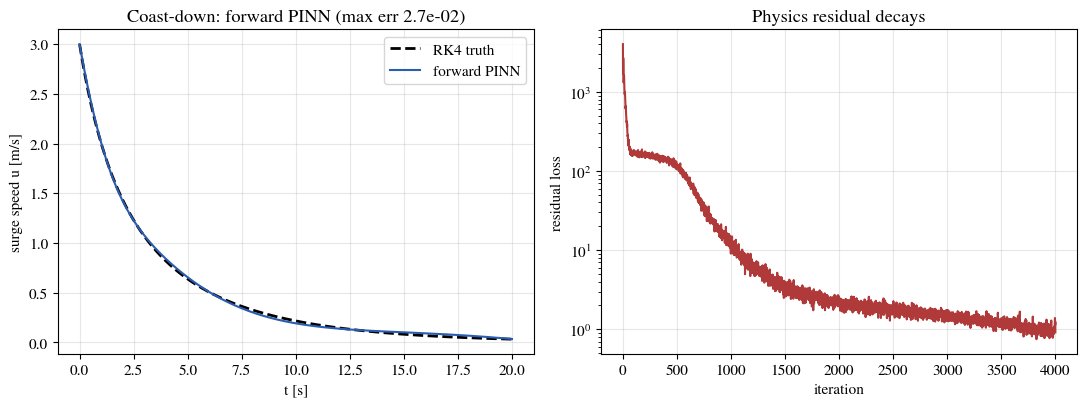

max abs error vs RK4: 0.02731652387679423


In [3]:
t_gt, Z = vessel.simulate(lambda t, z: np.zeros(3),
                          z0=[0, 0, 0, U0, 0, 0], t_end=T, dt=0.01, p=p)
u_gt = Z[:, 3]

net = MLP([1, 32, 32, 1])
def u_hat(t): return U0 + t * net(t / T)
def loss_fwd():
    t = (torch.rand(2000, 1) * T).requires_grad_(True)
    u = u_hat(t); u_t = grad(u, t)
    return ((m11 * u_t + du_true * u + Xuu_true * torch.abs(u) * u) ** 2).mean()

hist = train(loss_fwd, net.parameters(), steps=STEPS_FWD, lr=2e-3)
tt = torch.linspace(0, T, 300).reshape(-1, 1)
with torch.no_grad(): up = u_hat(tt).numpy().ravel()
maxerr = np.abs(np.interp(t_gt, tt.numpy().ravel(), up) - u_gt).max()

def plot_pinn_forward():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].plot(t_gt, u_gt, '--', color=fg(), lw=2, label='RK4 truth')
    ax[0].plot(tt.numpy().ravel(), up, 'C0', label='forward PINN')
    ax[0].set(xlabel='t [s]', ylabel='surge speed u [m/s]',
              title=f'Coast-down: forward PINN (max err {maxerr:.1e})'); ax[0].legend()
    ax[1].semilogy(hist, 'C3'); ax[1].set(xlabel='iteration', ylabel='residual loss',
                                          title='Physics residual decays')
    plt.tight_layout()

save_dual(plot_pinn_forward, 'pinn_forward', FIG)
plt.show()
print('max abs error vs RK4:', maxerr)

## 2. Inverse PINN — recover the damping $d_u$ from noisy data

Now $d_u$ is *unknown*. We make it a trainable parameter and minimize the physics residual
(with the trainable $d_u$) plus a data-misfit on sparse, noisy speed samples. Starting from a
deliberately wrong guess, $d_u$ converges to the true value as training proceeds.

/var/folders/px/kfx0kpc11td_5_f5ny95_wrh0000gn/T/ipykernel_9937/3436815369.py:28: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:837.)
  rec['du'].append(float(torch.exp(log_du))); rec['Xuu'].append(float(torch.exp(log_Xuu)))


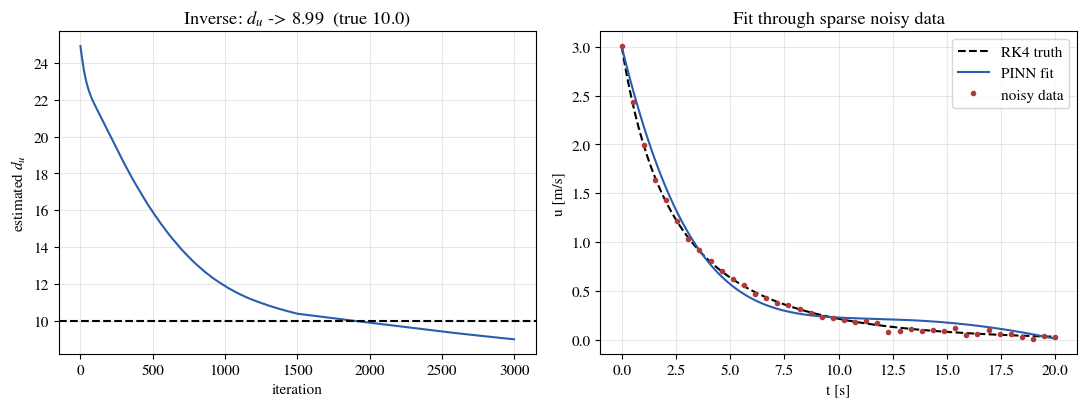

In [4]:
def run_inverse(u0v, fit_params, data_noise=NOISE, nd=N_DATA, steps=STEPS_INV, seed=0,
                init=dict(du=25.0, Xuu=12.0)):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    tg, Zg = vessel.simulate(lambda t, z: np.zeros(3),
                             z0=[0, 0, 0, u0v, 0, 0], t_end=T, dt=0.01, p=p)
    ug = Zg[:, 3]
    idx = np.linspace(0, len(tg) - 1, nd).astype(int)
    td = torch.tensor(tg[idx]).reshape(-1, 1)
    ud = torch.tensor(ug[idx] + data_noise * rng.standard_normal(nd)).reshape(-1, 1)
    n2 = MLP([1, 32, 32, 1])
    def uh(t): return u0v + t * n2(t / T)
    log_du = torch.tensor(np.log(init['du']), requires_grad=True)
    log_Xuu = torch.tensor(np.log(init['Xuu']), requires_grad=True)
    params = list(n2.parameters())
    if 'du' in fit_params: params.append(log_du)
    if 'Xuu' in fit_params: params.append(log_Xuu)
    opt = torch.optim.Adam(params, lr=3e-3)
    sched = torch.optim.lr_scheduler.StepLR(opt, 1500, 0.5)
    rec = {'du': [], 'Xuu': []}
    for k in range(steps):
        du = torch.exp(log_du) if 'du' in fit_params else torch.tensor(du_true)
        Xuu = torch.exp(log_Xuu) if 'Xuu' in fit_params else torch.tensor(Xuu_true)
        t = (torch.rand(1500, 1) * T).requires_grad_(True)
        u = uh(t); u_t = grad(u, t)
        Lr = ((m11 * u_t + du * u + Xuu * torch.abs(u) * u) ** 2).mean()
        Ld = ((uh(td) - ud) ** 2).mean()
        opt.zero_grad(); (Lr + 10.0 * Ld).backward(); opt.step(); sched.step()
        rec['du'].append(float(torch.exp(log_du))); rec['Xuu'].append(float(torch.exp(log_Xuu)))
    with torch.no_grad(): ufit = uh(torch.linspace(0, T, 300).reshape(-1, 1)).numpy().ravel()
    return rec, (tg, ug, td.numpy().ravel(), ud.numpy().ravel(), ufit)

rec, data = run_inverse(U0, fit_params=['du'], steps=STEPS_INV, seed=SEED + 1)
tg, ug, td, ud, ufit = data

def plot_pinn_inverse():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].plot(rec['du'], 'C0'); ax[0].axhline(du_true, ls='--', c=fg())
    ax[0].set(xlabel='iteration', ylabel='estimated $d_u$',
              title=f"Inverse: $d_u$ -> {rec['du'][-1]:.2f}  (true {du_true})")
    ax[1].plot(tg, ug, '--', color=fg(), label='RK4 truth'); ax[1].plot(np.linspace(0, T, 300), ufit, 'C0', label='PINN fit')
    ax[1].plot(td, ud, 'C3.', ms=6, label='noisy data')
    ax[1].set(xlabel='t [s]', ylabel='u [m/s]', title='Fit through sparse noisy data'); ax[1].legend()
    plt.tight_layout()

save_dual(plot_pinn_inverse, 'pinn_inverse', FIG)
plt.show()

## 3. Identifiability — excitation decides what data can pin down

The quadratic drag $X_{u|u|}|u|u$ only acts when $|u|$ is large. Identify **both** $d_u$ and
$X_{u|u|}$ from coast-downs that start slow ($u_0=1$, the quadratic term barely acts) versus
fast ($u_0=5$, it acts strongly). Repeating over noise realizations: a *slow* maneuver leaves
the two damping terms **correlated** --- at small $|u|$ the linear and quadratic drag are nearly
indistinguishable, so both estimates are wide and biased. A *fast* maneuver excites the
quadratic term, separating the two and pinning both down. The lesson: data informs a parameter
only if the maneuver makes the dynamics sensitive to it.

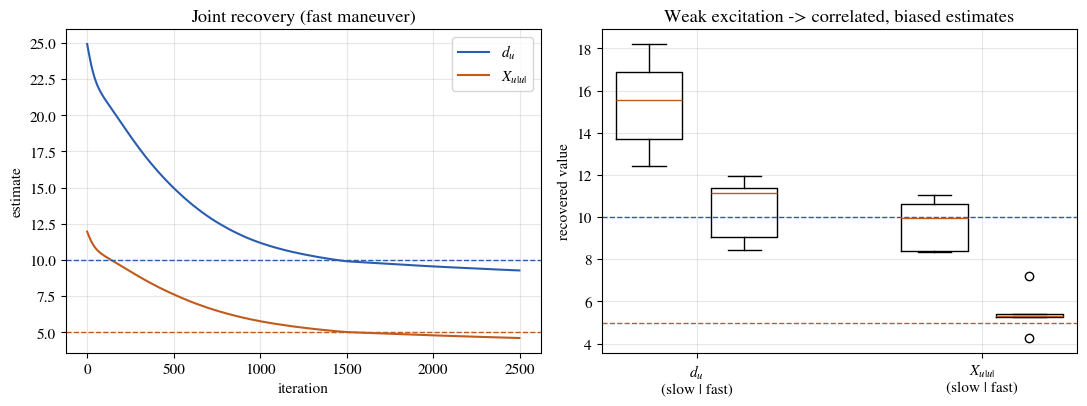

spread (std) du  slow: 2.09  fast: 1.38
spread (std) Xuu slow: 1.12  fast: 0.96


In [5]:
def ensemble(u0v, seeds=range(N_ENSEMBLE)):
    out = {'du': [], 'Xuu': []}
    for s in seeds:
        rec, _ = run_inverse(u0v, fit_params=['du', 'Xuu'], steps=2000, seed=SEED + 10 + s)
        out['du'].append(rec['du'][-1]); out['Xuu'].append(rec['Xuu'][-1])
    return out

slow, fast = ensemble(U0_SLOW), ensemble(U0_FAST)
rec_conv, _ = run_inverse(U0_FAST, fit_params=['du', 'Xuu'], steps=2500, seed=SEED)

def plot_pinn_identifiability():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].plot(rec_conv['du'], 'C0', label='$d_u$'); ax[0].plot(rec_conv['Xuu'], 'C1', label='$X_{u|u|}$')
    ax[0].axhline(du_true, ls='--', c='C0', lw=1); ax[0].axhline(Xuu_true, ls='--', c='C1', lw=1)
    ax[0].set(xlabel='iteration', ylabel='estimate', title='Joint recovery (fast maneuver)'); ax[0].legend()
    pos = [1, 2, 4, 5]
    bp = ax[1].boxplot([slow['du'], fast['du'], slow['Xuu'], fast['Xuu']], positions=pos, widths=0.7)
    ax[1].axhline(du_true, ls='--', c='C0', lw=1); ax[1].axhline(Xuu_true, ls='--', c='C1', lw=1)
    ax[1].set_xticks([1.5, 4.5]); ax[1].set_xticklabels(['$d_u$\n(slow | fast)', '$X_{u|u|}$\n(slow | fast)'])
    ax[1].set(ylabel='recovered value', title='Weak excitation -> correlated, biased estimates')
    plt.tight_layout()

save_dual(plot_pinn_identifiability, 'pinn_identifiability', FIG)
plt.show()
print('spread (std) du  slow:', np.std(slow['du']).round(2), ' fast:', np.std(fast['du']).round(2))
print('spread (std) Xuu slow:', np.std(slow['Xuu']).round(2), ' fast:', np.std(fast['Xuu']).round(2))

## 4. Full 3-DOF forward PINN — surge, sway and yaw, by time-marching

The same recipe scales to the coupled model: the network maps time to the body velocity
$\hat{\boldsymbol{\nu}}(t)\in\mathbb{R}^3$, with residual the full vector dynamics
$\mathbf{M}\dot{\hat{\boldsymbol{\nu}}}+\mathbf{C}(\hat{\boldsymbol{\nu}})\hat{\boldsymbol{\nu}}
+\mathbf{D}(\hat{\boldsymbol{\nu}})\hat{\boldsymbol{\nu}}-\boldsymbol{\tau}$. A *single* global
PINN struggles here: the fast spin-up violates temporal causality (the optimizer can satisfy
the late-time residual before the early transient is right) and it stalls. The cure is
**time-marching** --- split $[0,T]$ into short windows and solve them in order, each starting
from the previous window's end state. Each window is an easy short-horizon PINN, and together
they track the full maneuver to about one percent.

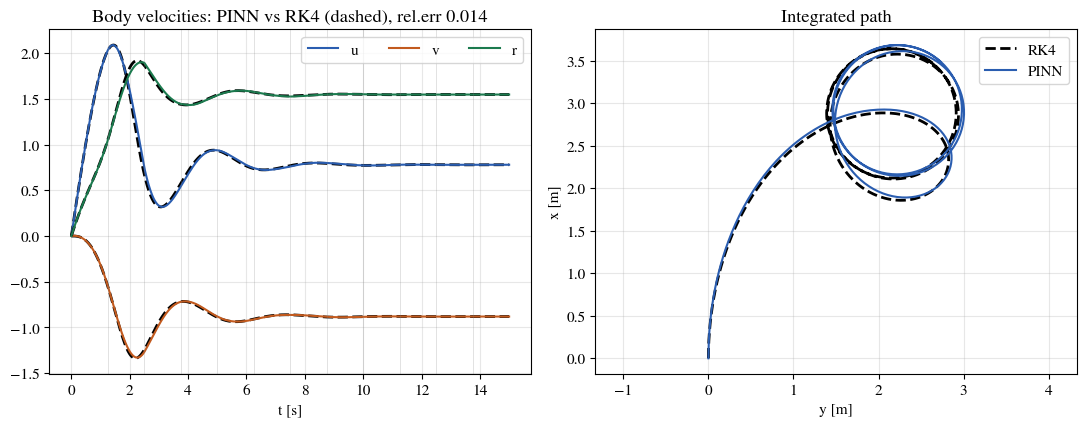

3-DOF velocity rel. error: 0.0137


In [6]:
m22, m33 = p.m - p.Y_vdot, p.Iz - p.N_rdot          # 80, 30
tau = torch.tensor([SURGE, 0.0, YAW])

def residual3(nuh, nud):
    u, v, r = nuh[:, 0:1], nuh[:, 1:2], nuh[:, 2:3]
    Cnu = torch.cat([-m22 * v * r, m11 * u * r, (m22 - m11) * u * v], 1)
    Dnu = torch.cat([(p.Du + p.Xuu * u.abs()) * u,
                     (p.Dv + p.Yvv * v.abs()) * v,
                     (p.Dr + p.Nrr * r.abs()) * r], 1)
    Mnud = torch.cat([m11 * nud[:, 0:1], m22 * nud[:, 1:2], m33 * nud[:, 2:3]], 1)
    return Mnud + Cnu + Dnu - tau

torch.manual_seed(SEED)
NW, DW = N_WINDOWS, T3 / N_WINDOWS   # time-marching windows
net3 = MLP([1, 32, 32, 3])    # warm-started across windows
nu_ic = torch.zeros(3); ts_all, nu_all = [], []
for i in range(NW):
    ic = nu_ic.detach().clone()
    def nu_hat(s): return ic + s * net3(s / DW)
    def lossw():
        s = (DW * torch.rand(1500, 1)).requires_grad_(True)
        nuh = nu_hat(s)
        nud = torch.cat([grad(nuh[:, j:j + 1], s) for j in range(3)], 1)
        return (residual3(nuh, nud) ** 2).mean()
    train(lossw, net3.parameters(), steps=STEPS_PER_WINDOW, lr=2e-3)
    ss = torch.linspace(0, DW, 60).reshape(-1, 1)
    with torch.no_grad(): nuw = nu_hat(ss)
    ts_all.append(np.linspace(i * DW, (i + 1) * DW, 60)); nu_all.append(nuw.numpy())
    nu_ic = nuw[-1]
tt = np.concatenate(ts_all); NUp = np.concatenate(nu_all)

t3, Z3 = vessel.simulate(vessel.turning_circle(SURGE, YAW), t_end=T3, dt=0.01, p=p)
NU_true = np.stack([np.interp(tt, t3, Z3[:, 3 + j]) for j in range(3)], 1)
relerr = np.linalg.norm(NUp - NU_true) / np.linalg.norm(NU_true)

# integrate pose from PINN velocities (uniform grid)
tu = np.linspace(0, T3, 600); NUu = np.stack([np.interp(tu, tt, NUp[:, j]) for j in range(3)], 1)
eta = np.zeros(3); E = [eta.copy()]; dtt = T3 / 599
for k in range(599):
    eta = eta + dtt * vessel.rotation(eta[2]) @ NUu[k]; E.append(eta.copy())
E = np.array(E)

def plot_pinn_forward3dof():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
    for j, lab in enumerate(['u', 'v', 'r']):
        ax[0].plot(t3, Z3[:, 3 + j], '--', color=fg(), lw=2)
        ax[0].plot(tt, NUp[:, j], color=f'C{j}', label=lab)
    for i in range(1, NW):
        ax[0].axvline(i * DW, color='gray', lw=0.4, alpha=0.4)
    ax[0].set(xlabel='t [s]', title=f'Body velocities: PINN vs RK4 (dashed), rel.err {relerr:.3f}')
    ax[0].legend(ncol=3)
    ax[1].plot(Z3[:, 1], Z3[:, 0], '--', color=fg(), lw=2, label='RK4'); ax[1].plot(E[:, 1], E[:, 0], 'C0', label='PINN')
    ax[1].axis('equal'); ax[1].legend(); ax[1].set(xlabel='y [m]', ylabel='x [m]', title='Integrated path')
    plt.tight_layout()

save_dual(plot_pinn_forward3dof, 'pinn_forward3dof', FIG)
plt.show()
print('3-DOF velocity rel. error:', round(float(relerr), 4))

## 5. Grey-box PINN — identify a misspecified physics term

Suppose the real vessel feels an extra drag $c\,u|u|$ the nominal model omits, so a pure forward
solve of the nominal physics overshoots the true speed. If we know the *form* of the missing
term but not its strength, we add it with a **trainable coefficient** $c_\theta$ and fit sparse
data: the PINN recovers both the trajectory and $c_\theta\approx c$. We hold the speed up with a
constant thrust so the drag stays excited (otherwise $c$ is unidentifiable, as in step 3). When
the correction's *form* is unknown, this becomes the learned source term of CoSTA
(Chapter~\ref{ch:costa}).

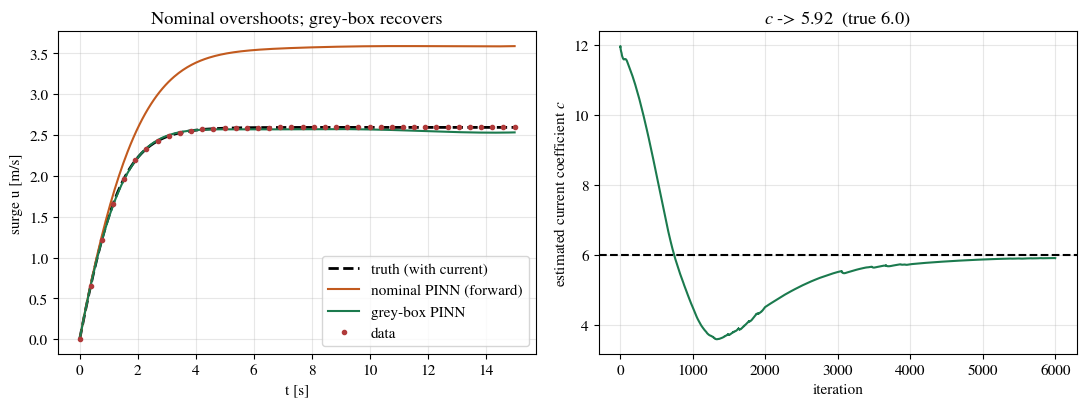

recovered c: 5.918


In [7]:
# truth: forced surge (constant thrust) with an unmodeled quadratic current drag c*u|u|
def surge_rhs(u): return (TAU1 - du_true * u - Xuu_true * abs(u) * u - C_TRUE * u * abs(u)) / m11
dt_h = 0.01; n_h = int(round(T5 / dt_h)); uval = 0.0; us = [uval]
for _ in range(n_h):
    k1 = surge_rhs(uval); k2 = surge_rhs(uval + 0.5 * dt_h * k1)
    k3 = surge_rhs(uval + 0.5 * dt_h * k2); k4 = surge_rhs(uval + dt_h * k3)
    uval = uval + dt_h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4); us.append(uval)
tth = np.linspace(0, T5, n_h + 1); uh_gt = np.array(us)
idx = np.linspace(0, len(tth) - 1, 40).astype(int)
tdh = torch.tensor(tth[idx]).reshape(-1, 1); udh = torch.tensor(uh_gt[idx]).reshape(-1, 1)

def fit_pinn(greybox):
    torch.manual_seed(SEED)
    net_u = MLP([1, 32, 32, 1]); c_th = torch.tensor(12.0, requires_grad=True)  # overestimate init
    def uh(t): return t * net_u(t / T5)
    if greybox:
        opt = torch.optim.Adam([{'params': net_u.parameters(), 'lr': 3e-3},
                                {'params': [c_th], 'lr': 4e-2}])
    else:
        opt = torch.optim.Adam(net_u.parameters(), lr=3e-3)
    sched = torch.optim.lr_scheduler.StepLR(opt, 2000, 0.5); rec = []
    for k in range(STEPS_GB):
        t = (torch.rand(1500, 1) * T5).requires_grad_(True)
        u = uh(t); u_t = grad(u, t)
        phys = m11 * u_t + du_true * u + Xuu_true * torch.abs(u) * u - TAU1
        if greybox:
            loss = ((phys + c_th * u * torch.abs(u)) ** 2).mean() + 300.0 * ((uh(tdh) - udh) ** 2).mean()
        else:
            loss = (phys ** 2).mean()           # pure forward solve of the NOMINAL physics
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        rec.append(float(c_th.detach()))
    grid = torch.linspace(0, T5, 300).reshape(-1, 1)
    with torch.no_grad(): uc = uh(grid).numpy().ravel()
    return uc, rec

u_nom, _ = fit_pinn(False)
u_gb, rec_c = fit_pinn(True)
gx = np.linspace(0, T5, 300)

def plot_pinn_hybrid():
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].plot(tth, uh_gt, '--', color=fg(), lw=2, label='truth (with current)')
    ax[0].plot(gx, u_nom, 'C1', label='nominal PINN (forward)')
    ax[0].plot(gx, u_gb, 'C2', label='grey-box PINN')
    ax[0].plot(tth[idx], uh_gt[idx], 'C3.', ms=6, label='data')
    ax[0].set(xlabel='t [s]', ylabel='surge u [m/s]',
              title='Nominal overshoots; grey-box recovers'); ax[0].legend()
    ax[1].plot(rec_c, 'C2'); ax[1].axhline(C_TRUE, ls='--', c=fg())
    ax[1].set(xlabel='iteration', ylabel='estimated current coefficient $c$',
              title=f"$c$ -> {rec_c[-1]:.2f}  (true {C_TRUE})")
    plt.tight_layout()

save_dual(plot_pinn_hybrid, 'pinn_hybrid', FIG)
plt.show()
print('recovered c:', round(rec_c[-1], 3))

In [8]:
assert np.isfinite(hist).all() and maxerr < 0.1, f"forward coast-down max error {maxerr:.3f}"
assert abs(rec['du'][-1] - du_true)/du_true < 0.15, f"d_u recovered as {rec['du'][-1]:.2f}"
assert np.isfinite(NUp).all() and relerr < 0.05, f"3-DOF time-marching rel. error {relerr:.3f}"
assert abs(rec_c[-1] - C_TRUE)/C_TRUE < 0.1, f"grey-box c recovered as {rec_c[-1]:.2f}"
if AT_DEFAULTS:
    # numbers quoted on the slides and in notes/applications.tex
    assert 0.02 < maxerr < 0.035, f"coast-down max error {maxerr:.4f}"
    assert np.std(slow['du']) > np.std(fast['du']), "slow maneuver leaves d_u less identifiable"
    assert 0.01 < relerr < 0.02, f"3-DOF rel. error {relerr:.4f}"
    assert abs(rec_c[-1] - 5.92) < 0.05, f"grey-box c {rec_c[-1]:.3f}"
    print(f"slide numbers: coast-down max err {maxerr:.3f}, d_u {rec['du'][-1]:.2f}, "
          f"3-DOF rel.err {relerr:.4f}, c {rec_c[-1]:.2f}")
else:
    print('regression check skipped (parameters differ from the slide defaults)')

slide numbers: coast-down max err 0.027, d_u 8.99, 3-DOF rel.err 0.0137, c 5.92


**Takeaways.** PINNs shine where black boxes struggle: they solve the forward problem to
solver accuracy with a hard-IC ansatz, *identify* physical parameters from sparse noisy data
(when the maneuver excites them), scale to the coupled 3-DOF dynamics via time-marching, and ---
in grey-box form --- identify a misspecified physics term. When the correction's functional form
is itself unknown, that is exactly CoSTA (Chapter~\ref{ch:costa}); recovering the learned term as
an equation is Chapter~\ref{ch:eqdiscovery}.